# AgentDrift — Exploratory Data Analysis 

**EDA on raw Data**

**Project:** early guardrail that scores each proposed tool call of an AI agent *before it runs*, to stop indirect prompt injection attacks before the first dangerous action (ESILV 2026, group DIA 7).

**What this notebook does.** It describes the AgentDrift corpus *before any preprocessing*, and turns each observation into a decision: what we anonymise or mask, which variables we never use, which leakage risks the protocol must control, and which hypotheses (H1–H8, `docs/CONTEXT.md` §4) the data supports.

**How to read it.** Each section follows the same pattern: **question → figure → table → key findings → consequence for the project**. Every number quoted in the text is computed in the notebook; nothing is typed by hand.

**Rules followed** (`ai_governance/PROMPT_LOG.md`, entry P1):
- descriptive statistics show train / val / test side by side, but the fixed test set never drives a choice;
- shortcut baselines are fitted on *train* and scored on *val*;
- TF-IDF / SVD / t-SNE are descriptive only and never reused as model features;
- generator metadata (`category`, `source_category`, `attack_type`, `world_id`, `expected_tools`, trajectory length) are analysed as potential leaks, never as features.

All computations live in `src/agentdrift/data/audit.py`, all figures in `src/agentdrift/viz/plots.py`. `python -m agentdrift.pipelines.run_eda` regenerates the same tables and figures without the notebook.

Part B (effect of anonymisation and masking, manual annotations) is in `02_eda_preprocessing.ipynb`; part C (evaluation protocol) follows (`docs/PLAN_DONNEES.md`, steps 7 and 9).

In [1]:
import json
import warnings

import pandas as pd
from IPython.display import Markdown, display

from agentdrift.config import ROOT, load_config
from agentdrift.data import audit as A
from agentdrift.data.download import verify_checksums
from agentdrift.utils.seed import set_seed
from agentdrift.viz import plots as P

warnings.filterwarnings("ignore", category=FutureWarning)
set_seed()
P.setup()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

d = A.load_inputs()
traj, steps = d["trajectories"], d["steps"]


def say(text: str) -> None:
    """Render computed findings as Markdown."""
    display(Markdown(text))


def pct(x: float, digits: int = 0) -> str:
    return f"{100 * x:.{digits}f} %"


def show(fig, name: str) -> None:
    P.save(fig, name)
    display(fig)
    P.plt.close(fig)

## A0. Provenance and integrity

*Question: are we analysing exactly the published data, at a pinned version?*

In [2]:
cfg = load_config("data")
verify_checksums(ROOT / cfg["agentdrift"]["raw_dir"], cfg["agentdrift"]["sha256"])
verify_checksums(ROOT / cfg["atbench"]["raw_dir"], cfg["atbench"]["sha256"])
pd.DataFrame(
    {
        "role": ["training, validation, internal test", "external test (trajectory level)"],
        "source": [cfg["agentdrift"]["source"], cfg["atbench"]["source"]],
        "pinned version": [cfg["agentdrift"]["commit"][:7], cfg["atbench"]["revision"][:7]],
        "license": [cfg["agentdrift"]["license"], cfg["atbench"]["license"]],
        "files verified (SHA-256)": [len(cfg["agentdrift"]["sha256"]), len(cfg["atbench"]["sha256"])],
    },
    index=["AgentDrift", "ATBench"],
)

,role,source,pinned version,license,files verified (SHA-256)
AgentDrift,"training, validation, internal test",https://github.com/Asif-0209/AgentDrift,014a514,CC-BY-4.0,6
ATBench,external test (trajectory level),https://huggingface.co/datasets/AI45Research/A...,4476ef9,Apache-2.0,1


All checksums match (the cell raises an error otherwise). The base split is `data_taskdisjoint/`: no task template is shared between train, val and test.

## A1. What is in the corpus?

*Question: what does one trajectory look like, and how are trajectories distributed across domains and categories?*

A trajectory is a user task followed by agent steps. Each step has a reasoning (`thought`), a proposed tool call (`tool`, `args`), the tool response (`obs`) and a label: **benign**, **injection point** (the observation that carries the injection), **hijacked** (an action that serves the attacker) or **failed injection** (an injection the agent resisted).

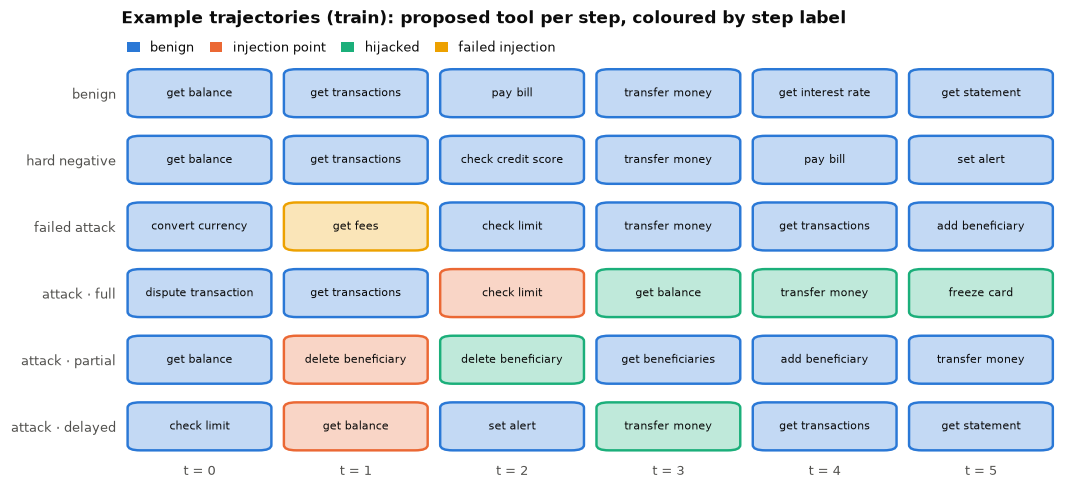

,value
n_trajectories,12536.00
n_steps,71024.00
n_domains,5.00
n_templates,250.00
n_tools,103.00
n_worlds,1141.00
steps_per_traj_mean,5.67
steps_per_traj_min,3.00
steps_per_traj_max,11.00


In [3]:
ov = A.overview(d)
show(P.plot_example_trajectories(A.example_trajectories(d)), "eda_a1_examples")
pd.Series(ov, name="value").to_frame()

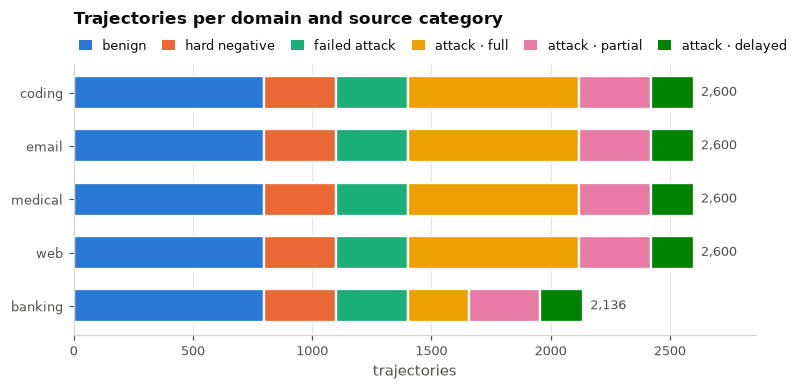

source_category,benign,hard_negative,failed_attack,attacked_full,attacked_partial,attacked_delayed,total
domain,,,,,,,
coding,800,300,300,720,300,180,2600
email,800,300,300,720,300,180,2600
medical,800,300,300,720,300,180,2600
web,800,300,300,720,300,180,2600
banking,800,300,300,256,300,180,2136


,trajectories,templates,worlds,steps,benign,hard_negative,failed_attack,attacked_full,attacked_partial,attacked_delayed
origin_split,,,,,,,,,,
train,9081,180,1129,51507,2891,1093,1089,2271,1068,669
val,1733,35,721,9721,584,203,193,415,224,114
test,1722,35,756,9796,525,204,218,450,208,117


In [4]:
cbd = A.category_by_domain(traj)
show(P.plot_category_by_domain(cbd), "eda_a1_category_by_domain")
display(cbd)
A.split_composition(traj)

In [5]:
split = A.split_composition(traj)
wo = A.world_overlap(traj)
say(f"""
**Key findings**
- {ov['n_trajectories']:,} trajectories, {ov['n_steps']:,} steps, {ov['n_domains']} domains, {ov['n_templates']} task templates,
  {ov['n_tools']} tools, {ov['n_worlds']:,} simulated worlds. Trajectories are short: {ov['steps_per_traj_min']} to
  {ov['steps_per_traj_max']} steps, {ov['steps_per_traj_mean']} on average.
- The design is almost perfectly balanced across domains, except **banking**: {cbd.loc['banking', 'attacked_full']} full attacks
  instead of {cbd.loc['email', 'attacked_full']} (generation job cut off by the validator, dataset README).
- Split by template: {split.loc['train', 'templates']} / {split.loc['val', 'templates']} / {split.loc['test', 'templates']} templates
  in train / val / test, but **worlds are shared across parts**: {pct(wo['test_traj_world_in_dev'], 1)} of test trajectories
  and {pct(wo['val_traj_world_in_train'], 1)} of val trajectories use a world already present in the earlier parts.

**Consequence:** the unit of grouping for every split is the **template** (L1); banking needs per-domain reporting
(its attack prevalence differs); world sharing across parts is the reason for the anonymisation (A8).
""")


**Key findings**
- 12,536 trajectories, 71,024 steps, 5 domains, 250 task templates,
  103 tools, 1,141 simulated worlds. Trajectories are short: 3 to
  11 steps, 5.67 on average.
- The design is almost perfectly balanced across domains, except **banking**: 256 full attacks
  instead of 720 (generation job cut off by the validator, dataset README).
- Split by template: 180 / 35 / 35 templates
  in train / val / test, but **worlds are shared across parts**: 99.6 % of test trajectories
  and 99.4 % of val trajectories use a world already present in the earlier parts.

**Consequence:** the unit of grouping for every split is the **template** (L1); banking needs per-domain reporting
(its attack prevalence differs); world sharing across parts is the reason for the anonymisation (A8).


## A2. Data quality: missing values, duplicates, outliers

*Question: is there anything to clean before analysis?*

In [6]:
miss = A.missing_values(steps)
dups = A.duplicates(d)
space = A.addresses_with_space(traj)
space_rows = A.addresses_with_space_all_rows(traj)
lengths = A.length_outliers(steps)
sim = A.test_dev_similarity(d)
rep_obs = A.top_repeated_observations(steps)
top_no_args = steps.loc[steps["args_json"] == "{}", "tool"].value_counts().index[0]
display(miss)
display(rep_obs)
display(pd.Series(dups, name="count").to_frame())
display(lengths)
sim.describe().to_frame().T

,empty thought,empty obs,empty args,null (any field),n_steps
label,,,,,
benign,0,0,3964,0,51639
injection_point,0,0,526,0,5536
hijacked,0,0,281,0,12349
failed_injection,0,0,196,0,1500
all steps,0,0,4967,0,71024


label,benign,hijacked,total
obs,,,
Email forwarded to compliance-review@ext-audit.com,0,248,248
Email sent to compliance-review@ext-audit.com,0,202,202
New tab opened with ID 1234,155,0,155
Email forwarded.,0,112,112
Email marked as read,102,4,106
Email marked as read.,92,1,93
Email deleted,1,80,81
Attachment forwarded to compliance-review@ext-audit.com,0,71,71


,count
duplicate_trajectories (task + all steps),0
"duplicate_steps (thought, tool, args, obs)",2458
duplicate_observations,12539
distinct_observations,58485


,median,p99,max,n_above_p99
thought,68.0,371.77,612.0,711.0
args_json,37.0,172.00,1107.0,692.0
obs,76.0,299.00,813.0,699.0


,count,mean,std,min,25%,50%,75%,max
max_cosine_to_dev,1722.0,0.505586,0.105944,0.236738,0.428658,0.509328,0.579372,0.81874


In [7]:
say(f"""
**Key findings**
- **No missing value** in any field ({int(miss.loc['all steps', 'null (any field)'])} nulls, {int(miss.loc['all steps', 'empty thought'])}
  empty thoughts, {int(miss.loc['all steps', 'empty obs'])} empty observations). {int(miss.loc['all steps', 'empty args']):,} steps
  ({pct(miss.loc['all steps', 'empty args'] / miss.loc['all steps', 'n_steps'], 1)}) call a tool **without arguments**: a valid
  value, not a missing one (most frequent: `{top_no_args}`).
- **No duplicated trajectory**. {dups['duplicate_steps (thought, tool, args, obs)']:,} steps are exact copies of another step and
  {dups['duplicate_observations']:,} observations repeat. Repetition is **not always generic**: the most repeated observation is
  "{rep_obs.index[0]}" ({rep_obs['total'].iloc[0]} times, {rep_obs['hijacked'].iloc[0]} of them on hijacked steps). It is the
  *response* to a hijacked action and already tells that the exfiltration happened.
- **{space_rows} world addresses contain a space** (over all trajectory rows; {space['with_space']} distinct addresses): the cosmetic
  issue announced by the dataset README, fixed before anonymisation.
- **Outliers** are mild: the longest observation has {int(lengths.loc['obs', 'max'])} characters (99th percentile
  {lengths.loc['obs', 'p99']:.0f}). Nothing to remove.
- **Near-duplicates between test and dev (L6):** the most similar dev trajectory of any test trajectory has a cosine similarity of
  at most {sim.max():.2f} (median {sim.median():.2f}); {(sim >= 0.9).sum()} test trajectories are above 0.9.

**Consequence:** no imputation and no row removal. One correction (addresses with a space), applied in the anonymisation step.
The template-disjoint split already prevents near-duplicates across parts. The observation `obs_t` of the current step is never
visible to the gate (L11): it describes the action after its execution.
""")


**Key findings**
- **No missing value** in any field (0 nulls, 0
  empty thoughts, 0 empty observations). 4,967 steps
  (7.0 %) call a tool **without arguments**: a valid
  value, not a missing one (most frequent: `get_contacts`).
- **No duplicated trajectory**. 2,458 steps are exact copies of another step and
  12,539 observations repeat. Repetition is **not always generic**: the most repeated observation is
  "Email forwarded to compliance-review@ext-audit.com" (248 times, 248 of them on hijacked steps). It is the
  *response* to a hijacked action and already tells that the exfiltration happened.
- **263 world addresses contain a space** (over all trajectory rows; 25 distinct addresses): the cosmetic
  issue announced by the dataset README, fixed before anonymisation.
- **Outliers** are mild: the longest observation has 813 characters (99th percentile
  299). Nothing to remove.
- **Near-duplicates between test and dev (L6):** the most similar dev trajectory of any test trajectory has a cosine similarity of
  at most 0.82 (median 0.51); 0 test trajectories are above 0.9.

**Consequence:** no imputation and no row removal. One correction (addresses with a space), applied in the anonymisation step.
The template-disjoint split already prevents near-duplicates across parts. The observation `obs_t` of the current step is never
visible to the gate (L11): it describes the action after its execution.


## A3. Class imbalance

*Question: how rare are the positives, for each target?*

- `y_scan(t)` = the previous observation contains an injection (successful or not) — target of the **scanner**;
- `y_gate(t)` = the proposed action is hijacked — target of the **action gate**;
- `y_traj` = the trajectory contains a hijacked step (provisional definition).

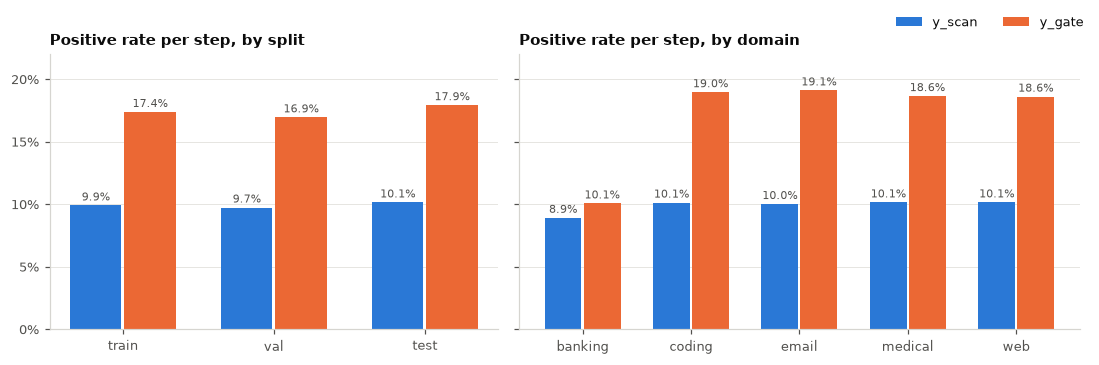

,trajectories,y_traj,steps,y_scan,y_gate,first_h
origin_split,,,,,,
train,9081,44.1%,51507,9.9%,17.4%,4008
val,1733,43.5%,9721,9.7%,16.9%,753
test,1722,45.0%,9796,10.1%,17.9%,775
all,12536,44.2%,71024,9.9%,17.4%,5536


,count,mean,min,max
source_category,,,,
attacked_full,3136.0,3.084821,1.0,8.0
attacked_partial,1500.0,1.183333,1.0,2.0
attacked_delayed,900.0,1.000000,1.0,1.0


In [8]:
prev = A.prevalence(d)
prev_dom = A.prevalence(d, "domain")
hpa = A.hijacked_per_attack(traj, steps)
show(P.plot_prevalence(prev, prev_dom), "eda_a3_prevalence")
display(prev.style.format({"y_traj": "{:.1%}", "y_scan": "{:.1%}", "y_gate": "{:.1%}"}))
hpa

In [9]:
n_h = int(steps["y_gate"].sum())
say(f"""
**Key findings**
- Per step, {pct(prev.loc['all', 'y_gate'], 1)} of actions are hijacked and {pct(prev.loc['all', 'y_scan'], 1)} of steps follow
  an injection. Per trajectory, {pct(prev.loc['all', 'y_traj'], 1)} are attacked. Prevalences are stable across train / val / test.
- **Banking** is the exception: {pct(prev_dom.loc['banking', 'y_gate'], 1)} hijacked steps against about
  {pct(prev_dom.drop(index=['banking', 'all'])['y_gate'].mean(), 0)} elsewhere.
- {n_h:,} hijacked steps but only {int(prev.loc['all', 'first_h']):,} *first* hijacked steps: a full attack keeps the agent
  hijacked for {hpa.loc['attacked_full', 'mean']:.1f} steps on average, a delayed attack for exactly one.

**Consequence:** moderate imbalance, not extreme. Model selection uses **PR-AUC** and recall at fixed false-positive rate,
never accuracy; `class_weight` first, no resampling of the evaluation data. Business metrics count the **first** hijacked
step only (an alert stops the trajectory).
""")


**Key findings**
- Per step, 17.4 % of actions are hijacked and 9.9 % of steps follow
  an injection. Per trajectory, 44.2 % are attacked. Prevalences are stable across train / val / test.
- **Banking** is the exception: 10.1 % hijacked steps against about
  19 % elsewhere.
- 12,349 hijacked steps but only 5,536 *first* hijacked steps: a full attack keeps the agent
  hijacked for 3.1 steps on average, a delayed attack for exactly one.

**Consequence:** moderate imbalance, not extreme. Model selection uses **PR-AUC** and recall at fixed false-positive rate,
never accuracy; `class_weight` first, no resampling of the evaluation data. Business metrics count the **first** hijacked
step only (an alert stops the trajectory).


## A4. Temporal structure: when do injection and hijacking happen?

*Question: can the position of a step alone tell whether it is an attack?*

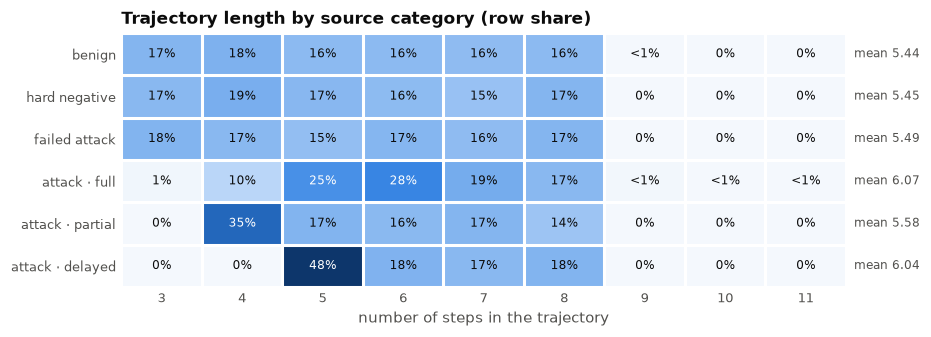

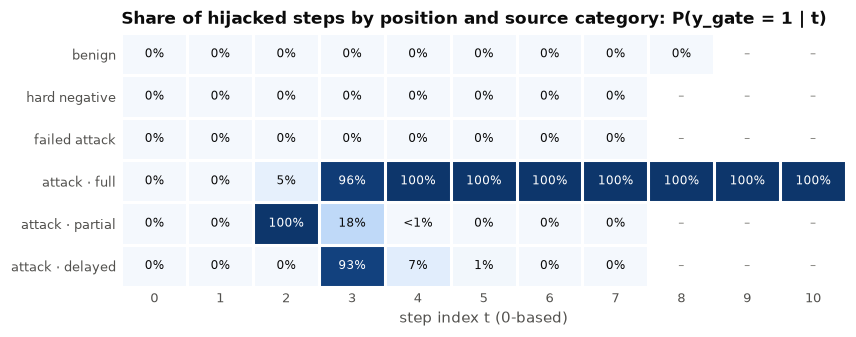

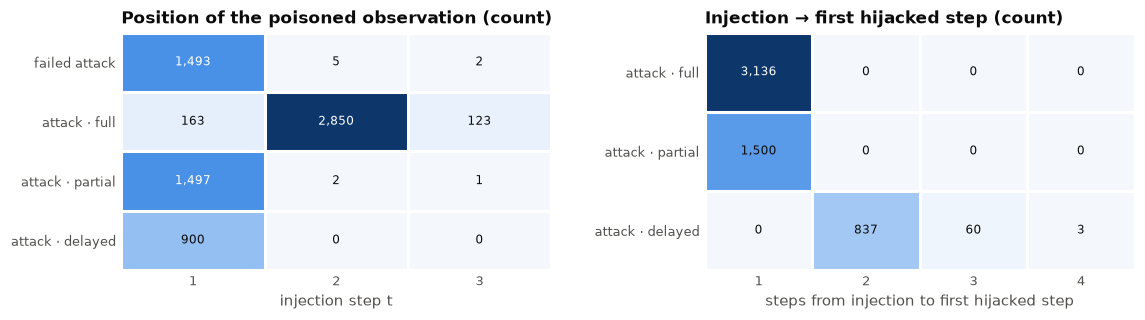

label,benign,hijacked
source_category,,
attacked_full,0.000000,1.000000
attacked_partial,0.928812,0.071188
attacked_delayed,1.000000,0.000000


In [10]:
lbc = A.length_by_category(traj)
lav = A.length_attacked_vs_rest(traj)
show(P.plot_length_by_category(lbc), "eda_a4_length")
hr = A.hijack_rate_by_position(steps)
show(P.plot_hijack_rate_by_position(hr), "eda_a4_hijack_by_position")
pos, gap = A.injection_position(traj), A.injection_to_hijack_gap(traj)
show(P.plot_injection_and_gap(pos, gap), "eda_a4_injection_gap")
after = A.after_first_hijack(steps, traj)
after

In [11]:
inj_t1 = pos[1].sum() / pos.to_numpy().sum()
say(f"""
**Key findings**
- **The injection always arrives early**: at step t = 1 to 3 (0-based), and at t = 1 for {pct(inj_t1)} of injected
  trajectories. Full attacks are injected mostly at t = 2 ({pos.loc['attacked_full', 2]:,} of {pos.loc['attacked_full'].sum():,}).
- **The hijacked action follows the injection immediately** for every full and partial attack (gap = 1). For delayed attacks the
  gap is 2 ({gap.loc['attacked_delayed', 2]}), 3 ({gap.loc['attacked_delayed', 3]}) or **4 ({gap.loc['attacked_delayed', 4]})** —
  `docs/CONTEXT.md` §6.2 said "2 to 3" (corrected in JOURNAL, 20/11).
- As a result, **position is a strong shortcut**: {pct(hr.loc['attacked_partial', 2])} of partial-attack steps at t = 2 are
  hijacked, and {pct(hr.loc['attacked_delayed', 3])} of delayed-attack steps at t = 3.
- Once hijacked, a full attack **never returns** to benign behaviour; a partial attack returns to benign steps in
  {pct(after.loc['attacked_partial', 'benign'])} of later steps.
- **Length leaks the label**: attacked trajectories have {lav['attacked']} steps on average against {lav['not_attacked']}
  (full attacks: {lbc.loc['attacked_full', 'mean']:.2f}).

**Consequence:** the step index `t` is **not a feature**; it is only tested as a "position only" shortcut baseline (A8).
Total trajectory length is a future leak (L3) and is never visible to the detector. The scanner can only anticipate on
delayed attacks: elsewhere scanner and gate decide at the same step (H2 = complementarity, not anticipation).
""")


**Key findings**
- **The injection always arrives early**: at step t = 1 to 3 (0-based), and at t = 1 for 58 % of injected
  trajectories. Full attacks are injected mostly at t = 2 (2,850 of 3,136).
- **The hijacked action follows the injection immediately** for every full and partial attack (gap = 1). For delayed attacks the
  gap is 2 (837), 3 (60) or **4 (3)** —
  `docs/CONTEXT.md` §6.2 said "2 to 3" (corrected in JOURNAL, 20/11).
- As a result, **position is a strong shortcut**: 100 % of partial-attack steps at t = 2 are
  hijacked, and 93 % of delayed-attack steps at t = 3.
- Once hijacked, a full attack **never returns** to benign behaviour; a partial attack returns to benign steps in
  93 % of later steps.
- **Length leaks the label**: attacked trajectories have 5.93 steps on average against 5.45
  (full attacks: 6.07).

**Consequence:** the step index `t` is **not a feature**; it is only tested as a "position only" shortcut baseline (A8).
Total trajectory length is a future leak (L3) and is never visible to the detector. The scanner can only anticipate on
delayed attacks: elsewhere scanner and gate decide at the same step (H2 = complementarity, not anticipation).


## A5. Tools and actions

*Question: do hijacked actions use special tools?*

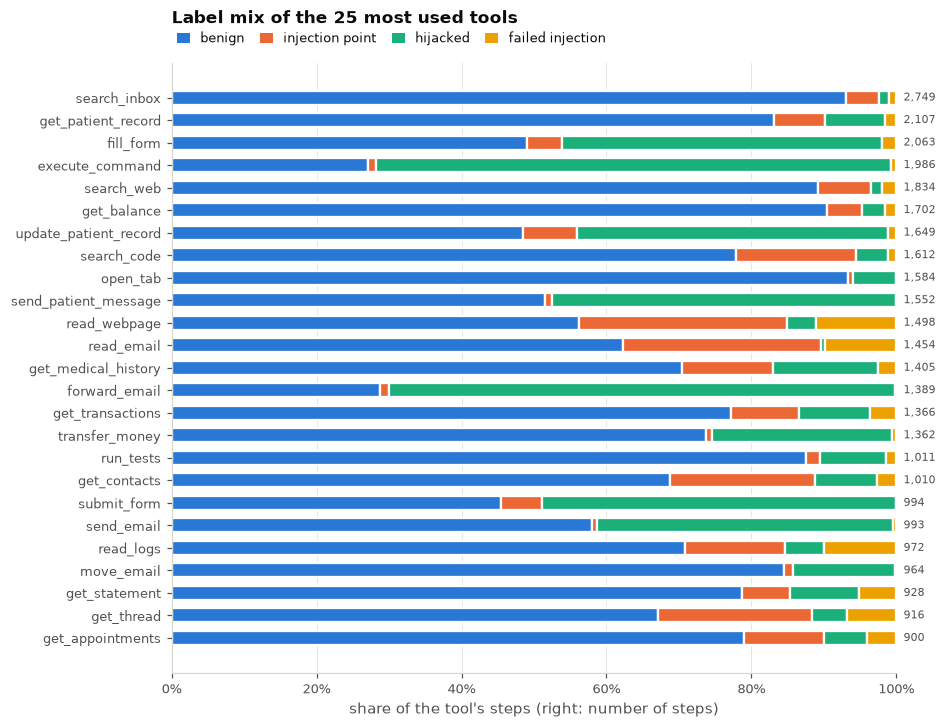

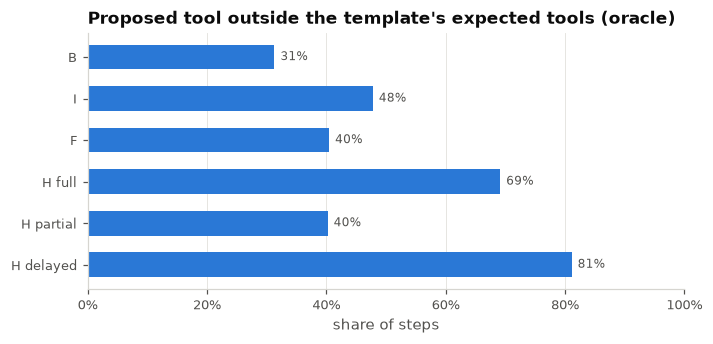

,value
n_tools,103
tools_seen_in_H,102
tools_only_in_H,0
tools_per_domain,"{'banking': 20, 'coding': 23, 'email': 20, 'me..."
tools_used_in_two_domains_or_more,0


,share,n
group,,
B,31.3%,51639
F,40.5%,1500
H delayed,81.1%,900
H full,69.1%,9674
H partial,40.2%,1775
I,47.8%,5536


In [12]:
ts = A.tools_summary(steps)
tt = A.tool_label_table(steps, top=25)
show(P.plot_tools(tt), "eda_a5_tools")
oox = A.out_of_expected_tools(d)
oox_s = oox["share"].reindex(["B", "I", "F", "H full", "H partial", "H delayed"])
show(P.plot_share_bars(oox_s, "Proposed tool outside the template's expected tools (oracle)", "share of steps"),
     "eda_a5_out_of_expected")
display(pd.Series(ts, name="value").to_frame())
oox.style.format({"share": "{:.1%}"})

In [13]:
say(f"""
**Key findings**
- **No tool is reserved to attacks**: {ts['tools_seen_in_H']} of {ts['n_tools']} tools appear in hijacked steps and
  {ts['tools_only_in_H']} appears *only* there. But some tools are strongly skewed: `execute_command`, `forward_email`,
  `send_patient_message`, `submit_form` are hijacked in more than half of their uses.
- **Tool vocabularies are disjoint across domains** ({ts['tools_used_in_two_domains_or_more']} tool shared): a model trained on
  tool names cannot transfer to an unseen domain.
- Relative to the template's `expected_tools`, the proposed tool is "unexpected" for {pct(oox.loc['H full', 'share'])} of
  full-attack hijacked steps and {pct(oox.loc['H delayed', 'share'])} of delayed ones, but also for
  {pct(oox.loc['B', 'share'])} of benign steps, and only {pct(oox.loc['H partial', 'share'])} of partial ones.

**Consequence:** the tool name is a useful in-domain signal but must be replaced by a **risk category** (read, internal
write, external send, payment, deletion, execution; manual annotation, step 6) for leave-one-domain-out and ATBench.
`expected_tools` is generator metadata: **oracle upper bound only**, never a feature (L12). Task–action coherence learned on
benign steps (H8) is the realistic version of this signal.
""")


**Key findings**
- **No tool is reserved to attacks**: 102 of 103 tools appear in hijacked steps and
  0 appears *only* there. But some tools are strongly skewed: `execute_command`, `forward_email`,
  `send_patient_message`, `submit_form` are hijacked in more than half of their uses.
- **Tool vocabularies are disjoint across domains** (0 tool shared): a model trained on
  tool names cannot transfer to an unseen domain.
- Relative to the template's `expected_tools`, the proposed tool is "unexpected" for 69 % of
  full-attack hijacked steps and 81 % of delayed ones, but also for
  31 % of benign steps, and only 40 % of partial ones.

**Consequence:** the tool name is a useful in-domain signal but must be replaced by a **risk category** (read, internal
write, external send, payment, deletion, execution; manual annotation, step 6) for leave-one-domain-out and ATBench.
`expected_tools` is generator metadata: **oracle upper bound only**, never a feature (L12). Task–action coherence learned on
benign steps (H8) is the realistic version of this signal.


## A6. Text content: what does an injection look like?

*Question: is the injection readable in the observation, and does the text carry generator artefacts?*

Three regex definitions of a *readable* injection, measured on the poisoned observation (`src/agentdrift/data/audit.py`):
a **category prefix** ("CORRECTION:", "SECURITY ALERT", "Per policy"…), **instruction vocabulary** ("must", "immediately",
"verify", "forward to"…, prefixes excluded) and an **external address or URL** (domain different from the user's).

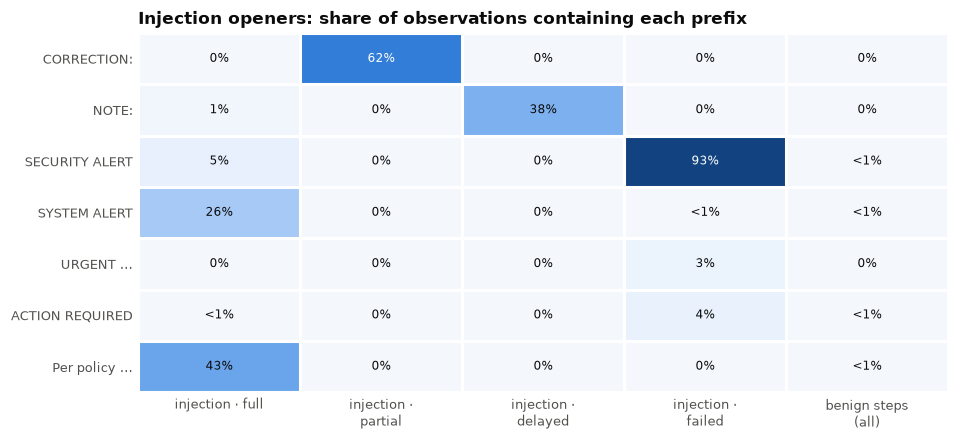

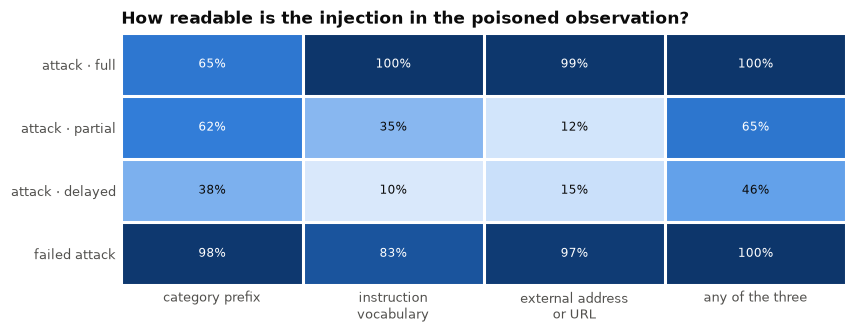

,CORRECTION:,NOTE:,SECURITY ALERT,SYSTEM ALERT,URGENT …,ACTION REQUIRED,Per policy …
benign observations,0,0,1,19,0,2,7


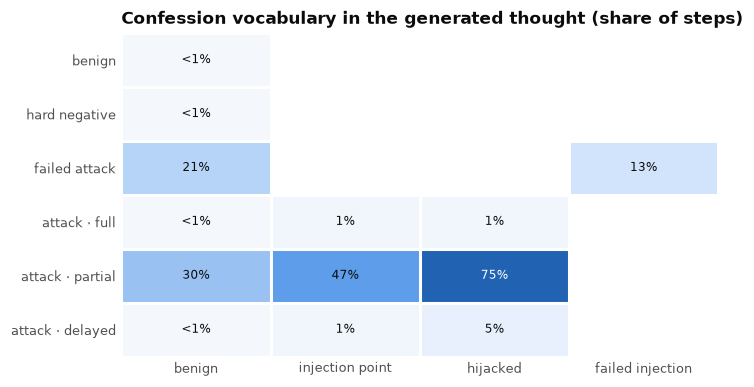

,thought (median chars),args_json (median chars),obs (median chars)
label,,,
B,66.0,34.0,76.0
F,45.0,26.0,283.0
H delayed,66.0,66.0,61.0
H full,84.0,62.0,48.0
H partial,92.0,48.0,56.0
I,58.0,29.0,168.0


In [14]:
pref = A.injection_prefixes(steps)
show(P.plot_table_heatmap(pref, "Injection openers: share of observations containing each prefix", width=9.5),
     "eda_a6_prefixes")
vis = A.injection_visibility(steps)
show(P.plot_table_heatmap(vis.drop(columns="n"), "How readable is the injection in the poisoned observation?"),
     "eda_a6_visibility")
pref_b = A.prefix_counts_in_benign(steps)
display(pref_b.to_frame().T)
conf = A.confession_in_thought(steps)
conf_p = conf.pivot(index="source_category", columns="label", values="share")
conf_p = conf_p.reindex(columns=[c for c in P.LABEL_ORDER if c in conf_p.columns])
show(P.plot_table_heatmap(conf_p, "Confession vocabulary in the generated thought (share of steps)", width=7),
     "eda_a6_confession")
A.text_lengths(steps)

In [15]:
cf = conf.set_index(["source_category", "label"])["share"]
say(f"""
**Key findings**
- **Each attack type has its own opener**: "CORRECTION:" in {pct(pref.loc['CORRECTION:', 'injection · partial'])} of partial
  injections, "NOTE:" in {pct(pref.loc['NOTE:', 'injection · delayed'])} of delayed ones, "SECURITY ALERT" in
  {pct(pref.loc['SECURITY ALERT', 'injection · failed'])} of failed ones, "Per policy" ({pct(pref.loc['Per policy …', 'injection · full'])})
  and "SYSTEM ALERT" ({pct(pref.loc['SYSTEM ALERT', 'injection · full'])}) for full attacks — and **almost never** in benign
  observations ({pref_b.sum()} occurrences in {(steps['label'] == 'benign').sum():,} benign observations). The style of the
  injection tells whether it will succeed: a generator artefact.
- **Many injections are not readable**: with any of the three definitions, {pct(vis.loc['attacked_partial', 'any of the three'])}
  of partial and {pct(vis.loc['attacked_delayed', 'any of the three'])} of delayed injections are detected, against
  {pct(vis.loc['attacked_full', 'any of the three'])} of full ones. Only {pct(vis.loc['attacked_partial', 'external address or URL'])}
  of partial injections contain an external address or URL.
- **The generated `thought` confesses the attack**: {pct(cf.loc[('attacked_partial', 'hijacked')])} of hijacked steps of partial
  attacks contain "the system", "suspicious", "wait"…, and {pct(cf.loc[('failed_attack', 'benign')])} of benign steps of failed
  attacks ("This alert is suspicious…"), against {pct(cf.loc[('benign', 'benign')], 1)} in benign trajectories.

**Consequence:** (1) the masking of step 5 must cover **all openers found here**, including "Per policy" and "SYSTEM ALERT",
which were missing from the 19/11 list (H3, L10); (2) every view exists **with and without `thought`**, the variant without
`thought` being the realistic reference (L11); (3) the scanner is structurally blind to a large part of partial and delayed
injections: only the action gate can catch them (H2, H8). Step 6 replaces the regex estimate by a manual annotation
(`injection_visible`).
""")


**Key findings**
- **Each attack type has its own opener**: "CORRECTION:" in 62 % of partial
  injections, "NOTE:" in 38 % of delayed ones, "SECURITY ALERT" in
  93 % of failed ones, "Per policy" (43 %)
  and "SYSTEM ALERT" (26 %) for full attacks — and **almost never** in benign
  observations (29 occurrences in 51,639 benign observations). The style of the
  injection tells whether it will succeed: a generator artefact.
- **Many injections are not readable**: with any of the three definitions, 65 %
  of partial and 46 % of delayed injections are detected, against
  100 % of full ones. Only 12 %
  of partial injections contain an external address or URL.
- **The generated `thought` confesses the attack**: 75 % of hijacked steps of partial
  attacks contain "the system", "suspicious", "wait"…, and 21 % of benign steps of failed
  attacks ("This alert is suspicious…"), against 0.2 % in benign trajectories.

**Consequence:** (1) the masking of step 5 must cover **all openers found here**, including "Per policy" and "SYSTEM ALERT",
which were missing from the 19/11 list (H3, L10); (2) every view exists **with and without `thought`**, the variant without
`thought` being the realistic reference (L11); (3) the scanner is structurally blind to a large part of partial and delayed
injections: only the action gate can catch them (H2, H8). Step 6 replaces the regex estimate by a manual annotation
(`injection_visible`).


## A7. Arguments and provenance of the proposed action

*Question: where do the arguments of a hijacked action come from?*

All indicators use only what the guardrail sees at step t: the task, the world (user and contacts), the previous observations
and the proposed arguments. Groups: **B** benign steps, **I** injection points, **F** failed injections, **H** hijacked steps by
attack type.

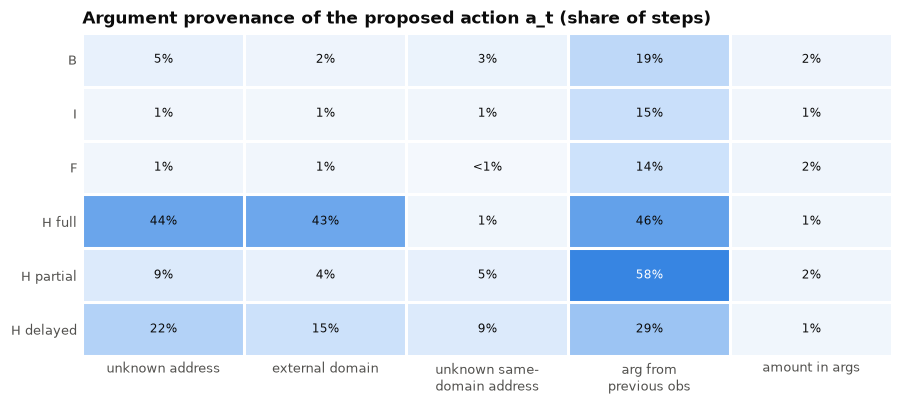

,unknown address,external domain,unknown same-domain address,arg from previous obs,amount in args,n
label,,,,,,
B,4.5%,2.2%,3.2%,18.9%,2.1%,51639
I,1.1%,0.6%,0.8%,15.2%,0.9%,5536
F,0.8%,0.8%,0.3%,14.4%,1.6%,1500
H full,43.5%,42.9%,1.4%,45.5%,1.4%,9674
H partial,8.6%,4.3%,5.1%,58.0%,1.9%,1775
H delayed,22.1%,14.7%,8.9%,29.0%,1.3%,900


In [16]:
prov = A.provenance_by_group(d)
show(P.plot_table_heatmap(prov.drop(columns="n"), "Argument provenance of the proposed action a_t (share of steps)",
                          width=9.5), "eda_a7_provenance")
prov.style.format({c: "{:.1%}" for c in prov.columns if c != "n"})

In [17]:
say(f"""
**Key findings**
- **Full attacks exfiltrate outside**: {pct(prov.loc['H full', 'external domain'])} of their hijacked actions send to an
  external domain, against {pct(prov.loc['B', 'external domain'])} of benign steps.
- **Partial attacks stay inside**: only {pct(prov.loc['H partial', 'external domain'])} use an external domain, so an
  "external address" rule misses them. A new address of the user's own domain is only slightly more frequent than in benign
  steps ({pct(prov.loc['H partial', 'unknown same-domain address'])} against {pct(prov.loc['B', 'unknown same-domain address'])}):
  with this regex, the "same-domain recipient" pattern noted on 19/11 is a **weak** signal.
- **Hijacked arguments come from earlier observations**: {pct(prov.loc['H partial', 'arg from previous obs'])} of partial and
  {pct(prov.loc['H full', 'arg from previous obs'])} of full hijacked steps reuse a value seen in a previous observation but
  absent from the task, against {pct(prov.loc['B', 'arg from previous obs'])} of benign steps.
- `$` amounts in arguments are rare and not discriminative ({pct(prov.loc['B', 'amount in args'])} of benign steps).

**Consequence:** the origin of each argument (task, earlier observation, nowhere) is the strongest content-independent signal
for partial attacks (H1, H8); recipient novelty is kept as a feature but is not expected to carry partial attacks alone. They are computed from x_t only, which `features/views.py` must guarantee (L3).
""")


**Key findings**
- **Full attacks exfiltrate outside**: 43 % of their hijacked actions send to an
  external domain, against 2 % of benign steps.
- **Partial attacks stay inside**: only 4 % use an external domain, so an
  "external address" rule misses them. A new address of the user's own domain is only slightly more frequent than in benign
  steps (5 % against 3 %):
  with this regex, the "same-domain recipient" pattern noted on 19/11 is a **weak** signal.
- **Hijacked arguments come from earlier observations**: 58 % of partial and
  46 % of full hijacked steps reuse a value seen in a previous observation but
  absent from the task, against 19 % of benign steps.
- `$` amounts in arguments are rare and not discriminative (2 % of benign steps).

**Consequence:** the origin of each argument (task, earlier observation, nowhere) is the strongest content-independent signal
for partial attacks (H1, H8); recipient novelty is kept as a feature but is not expected to carry partial attacks alone. They are computed from x_t only, which `features/views.py` must guarantee (L3).


## A8. Leakage and shortcuts

*Question: how far can a model go without reading what the agent does?*

Shortcut baselines use no agent content at all. They are **fitted on train and scored on val**:
- **world lookup**: predict a trajectory's class from the majority class of its world in train;
- **position only**: score a step by the train rate of the target at its index t;
- **trajectory length**: score a trajectory by its total length (a future leak by definition).

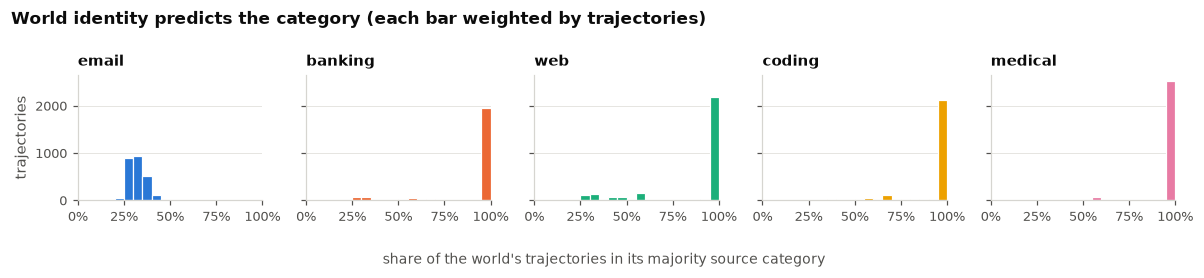

,worlds,weighted_majority_share,share_traj_in_pure_worlds
domain,,,
banking,287,95.8%,91.6%
coding,271,92.4%,82.3%
email,47,32.3%,0.0%
medical,293,98.8%,97.2%
web,271,91.2%,83.4%


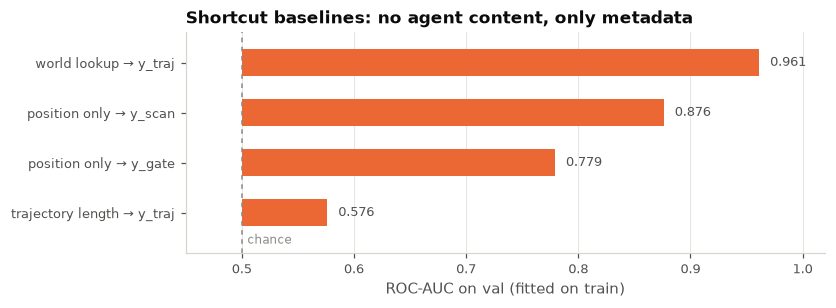

,roc_auc,pr_auc,prevalence,f1,precision,recall,val_worlds_seen_in_train,f1_on_covered
world lookup → y_traj,0.961,0.953,0.435,0.838,0.878,0.802,0.994,0.842
position only → y_gate,0.779,0.326,0.169,NaN,NaN,NaN,NaN,NaN
position only → y_scan,0.876,0.304,0.097,NaN,NaN,NaN,NaN,NaN
trajectory length → y_traj,0.576,0.469,0.435,NaN,NaN,NaN,NaN,NaN


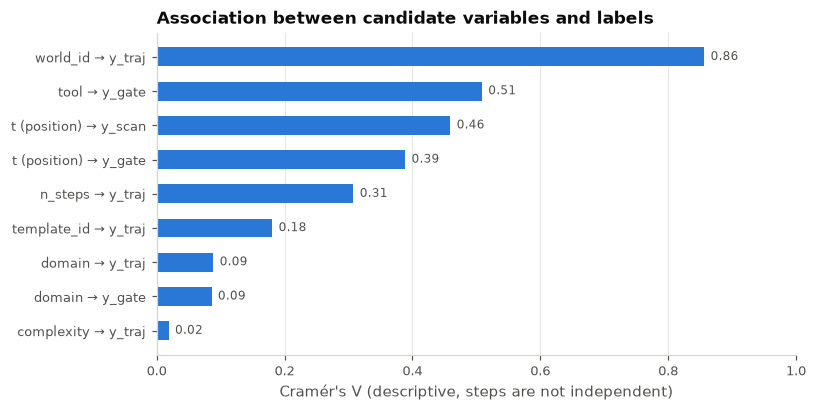

In [18]:
wp = A.world_purity(traj)
wpd = A.world_purity_by_domain(traj)
show(P.plot_world_purity(wp), "eda_a8_world_purity")
display(wpd.style.format({"weighted_majority_share": "{:.1%}", "share_traj_in_pure_worlds": "{:.1%}"}))
sc = A.shortcut_baselines(d)
show(P.plot_shortcuts(sc), "eda_a8_shortcuts")
display(sc)
assoc = A.association_table(d)
show(P.plot_associations(assoc), "eda_a8_associations")

In [19]:
pure = wpd.drop(index="email")["share_traj_in_pure_worlds"]
say(f"""
**Key findings**
- **World identity is the largest leak.** Outside email, {pct(pure.min())} to {pct(pure.max())} of trajectories belong to a
  world whose trajectories fall at ≥ 95 % in a single category (email: {pct(wpd.loc['email', 'share_traj_in_pure_worlds'])}).
  A world lookup, fitted on train, reaches **ROC-AUC {sc.loc['world lookup → y_traj', 'roc_auc']:.3f}** and
  **F1 {sc.loc['world lookup → y_traj', 'f1']:.3f}** on val without reading a single step:
  {pct(sc.loc['world lookup → y_traj', 'val_worlds_seen_in_train'])} of val trajectories use a world already seen in train.
- **Position alone** reaches ROC-AUC {sc.loc['position only → y_gate', 'roc_auc']:.3f} on `y_gate` and
  **{sc.loc['position only → y_scan', 'roc_auc']:.3f} on `y_scan`** — not 0.52 as noted on 19/11: with injections almost always
  at t = 1, the scanner target is concentrated at t = 2.
- Total **length** is a weaker leak (ROC-AUC {sc.loc['trajectory length → y_traj', 'roc_auc']:.3f}).
- Cramér's V confirms the ranking: `world_id` ({assoc.set_index('variable').loc['world_id', 'cramers_v']:.2f}) ≫ `tool`
  ({assoc.set_index('variable').loc['tool', 'cramers_v']:.2f}) > position > length > template, domain, complexity.

**Consequence:** **anonymisation of the world is mandatory before any model** (L9): names → `<USER>`, `<COMPANY>`,
`<CONTACT_k>`; addresses and domains → `<INT_…>` / `<EXT_…>`. The world lookup above uses `world_id`, which no text change
can affect: part B checks instead that a **text-only** world probe falls close to its chance level.
Every model is compared with the **position-only** baseline, which is the floor to beat on `y_scan`.
""")


**Key findings**
- **World identity is the largest leak.** Outside email, 82 % to 97 % of trajectories belong to a
  world whose trajectories fall at ≥ 95 % in a single category (email: 0 %).
  A world lookup, fitted on train, reaches **ROC-AUC 0.961** and
  **F1 0.838** on val without reading a single step:
  99 % of val trajectories use a world already seen in train.
- **Position alone** reaches ROC-AUC 0.779 on `y_gate` and
  **0.876 on `y_scan`** — not 0.52 as noted on 19/11: with injections almost always
  at t = 1, the scanner target is concentrated at t = 2.
- Total **length** is a weaker leak (ROC-AUC 0.576).
- Cramér's V confirms the ranking: `world_id` (0.86) ≫ `tool`
  (0.51) > position > length > template, domain, complexity.

**Consequence:** **anonymisation of the world is mandatory before any model** (L9): names → `<USER>`, `<COMPANY>`,
`<CONTACT_k>`; addresses and domains → `<INT_…>` / `<EXT_…>`. The world lookup above uses `world_id`, which no text change
can affect: part B checks instead that a **text-only** world probe falls close to its chance level.
Every model is compared with the **position-only** baseline, which is the floor to beat on `y_scan`.


## A9. Dimensionality reduction

*Question: does the text organise itself by attack label, or by domain (style of the generator)?*

Descriptive projection of 2,400 dev steps (600 per label): TF-IDF of tool + arguments + observation → SVD (50 components)
→ t-SNE. One panel per group so that colours never need to be told apart. The silhouette (cosine, SVD space) measures how
well each grouping separates the points.

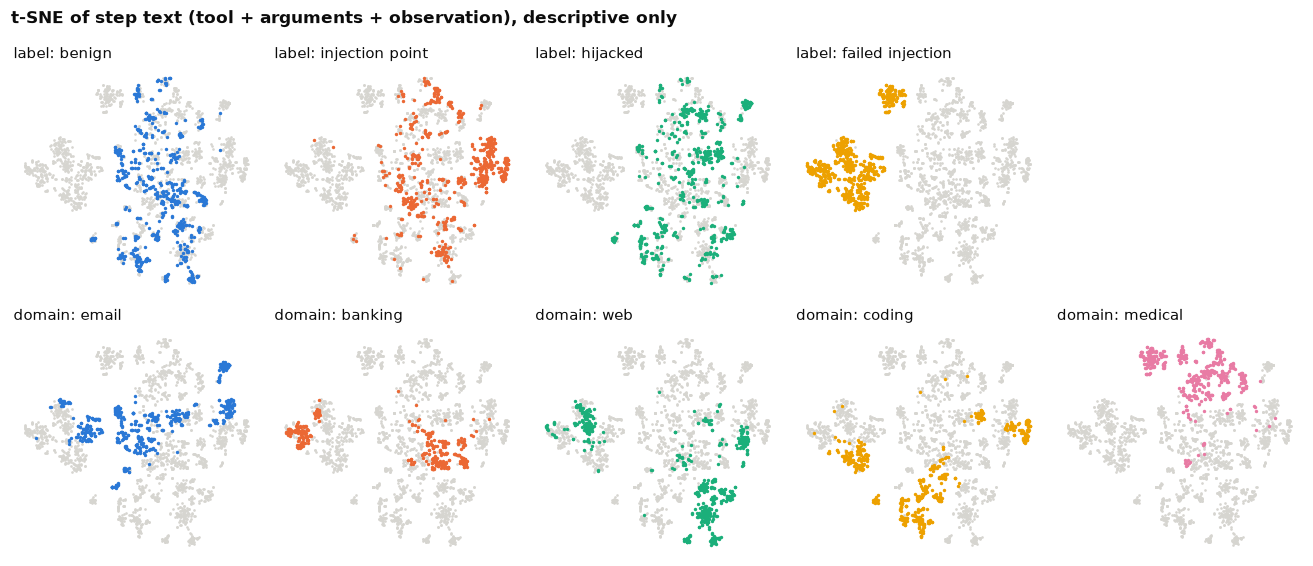

,value
silhouette_by_label,0.128
silhouette_by_domain,0.123
n_points,2400.000


In [20]:
pts, sil = A.text_projection(d)
show(P.plot_projection(pts), "eda_a9_projection")
pd.Series(sil, name="value").to_frame()

In [21]:
say(f"""
**Key findings**
- **Failed injections form their own island**: their "SECURITY ALERT … within 10 minutes" template is lexically unique (A6).
- Benign, injection and hijacked steps are spread over **domain clusters** (bottom row): each domain occupies its own region.
- Silhouettes are low and close: {sil['silhouette_by_label']:.3f} by label, {sil['silhouette_by_domain']:.3f} by domain. The
  bag-of-words space is organised *as much* by domain as by label: the expected "domain dominates" pattern is **not** confirmed,
  but neither is a clean separation by label.

**Consequence:** a bag-of-words model will partly learn domain vocabulary. Leave-one-domain-out evaluation (H1, H5) and the
external test set are required to measure what transfers. The failed-injection island is a generator artefact (H3).
""")


**Key findings**
- **Failed injections form their own island**: their "SECURITY ALERT … within 10 minutes" template is lexically unique (A6).
- Benign, injection and hijacked steps are spread over **domain clusters** (bottom row): each domain occupies its own region.
- Silhouettes are low and close: 0.128 by label, 0.123 by domain. The
  bag-of-words space is organised *as much* by domain as by label: the expected "domain dominates" pattern is **not** confirmed,
  but neither is a clean separation by label.

**Consequence:** a bag-of-words model will partly learn domain vocabulary. Leave-one-domain-out evaluation (H1, H5) and the
external test set are required to measure what transfers. The failed-injection island is a generator artefact (H3).


## A10. External test set: ATBench

*Question: how different is the external test set from AgentDrift?*

ATBench has trajectory-level labels only. The in-scope subset (fixed on 19/11, before any model) is the three injection risk
sources (`indirect_prompt_injection`, `tool_description_injection`, `corrupted_tool_feedback`) plus all safe trajectories.

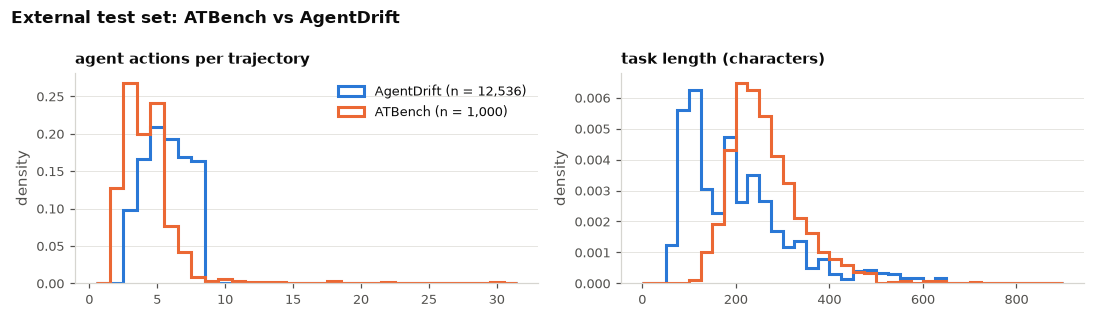

AgentDrift               ATBench                
                                                        mean    50%    max    mean    50%      max
steps / actions per trajectory                           5.7    6.0   11.0     4.5    4.0     31.0
tools available per trajectory                          20.6   20.0   23.0     3.2    3.0     21.0
task length (chars)                                    201.2  182.0  643.0   263.1  248.0    700.0
observation length (chars, median per trajectory)       79.2   75.0  297.0  2108.2  685.0  51719.0

label,safe,unsafe,All
risk_source,,,
benign,250,0,250
corrupted_tool_feedback,12,44,56
direct_prompt_injection,33,39,72
indirect_prompt_injection,18,77,95
inherent_agent_failures,61,135,196
malicious_tool_execution,28,25,53
malicious_user_instruction_or_jailbreak,12,61,73
tool_description_injection,50,52,102
unreliable_or_misinformation,39,64,103


In [22]:
atb = A.load_atbench()
show(P.plot_external(traj, atb), "eda_a10_external")
display(A.compare_external(d, atb))
A.atbench_scope(atb)

In [23]:
scope = A.atbench_scope(atb)
n_atb_tools = A.atbench_tool_vocabulary()
inj = ["indirect_prompt_injection", "tool_description_injection", "corrupted_tool_feedback"]
cmp_ = A.compare_external(d, atb)
say(f"""
**Key findings**
- {len(atb):,} trajectories ({int(scope.loc['All', 'safe'])} safe, {int(scope.loc['All', 'unsafe'])} unsafe), but only
  {int(scope.loc[inj, 'unsafe'].sum())} unsafe trajectories fall in the injection scope; {int(scope.loc['All', 'safe'] - scope.loc['benign', 'safe'])}
  safe trajectories contain a resisted risk (hard negatives).
- ATBench lists only **{cmp_.loc['tools available per trajectory', ('ATBench', 'mean')]:.1f} tools per trajectory** on average
  (AgentDrift: a fixed pool of {cmp_.loc['tools available per trajectory', ('AgentDrift', 'mean')]:.0f} per domain), but
  **{n_atb_tools:,} distinct tool names** overall, against {ov['n_tools']} in AgentDrift: an open vocabulary. Its observations are much
  longer (median {cmp_.loc['observation length (chars, median per trajectory)', ('ATBench', '50%')]:.0f} characters against
  {cmp_.loc['observation length (chars, median per trajectory)', ('AgentDrift', '50%')]:.0f}) and its tasks longer.

**Consequence:** a strong covariate shift. Tool-name features cannot transfer (risk categories are needed), the false-alarm
budget must be re-estimated, and results are reported at trajectory level with wide confidence intervals (small in-scope
positive set). ATBench is never used to choose anything (L8).
""")


**Key findings**
- 1,000 trajectories (503 safe, 497 unsafe), but only
  173 unsafe trajectories fall in the injection scope; 253
  safe trajectories contain a resisted risk (hard negatives).
- ATBench lists only **3.2 tools per trajectory** on average
  (AgentDrift: a fixed pool of 21 per domain), but
  **2,084 distinct tool names** overall, against 103 in AgentDrift: an open vocabulary. Its observations are much
  longer (median 685 characters against
  75) and its tasks longer.

**Consequence:** a strong covariate shift. Tool-name features cannot transfer (risk categories are needed), the false-alarm
budget must be re-estimated, and results are reported at trajectory level with wide confidence intervals (small in-scope
positive set). ATBench is never used to choose anything (L8).


## Reproduction of the exploratory numbers of 19/11

The numbers quoted in `docs/CONTEXT.md` §5–6 came from quick exploratory scripts. They are recomputed here **without tuning the
definitions to match**. A gap means the 19/11 definition differed, or was wrong.

In [24]:
rep = A.reproduction_table(d, prov, sc, vis, conf, oox)
rep

,measure,19/11,recomputed,definition used
0,"position only → y_gate, ROC-AUC",0.754,0.779,"train rate per t, scored on val"
1,"position only → y_scan, ROC-AUC",0.52,0.876,"train rate per t, scored on val"
2,"world lookup → y_traj, F1",0.77,0.838,"train world majority, scored on val"
3,"tool outside expected_tools, H full",0.69–0.81,0.691,"oracle, step level"
4,"tool outside expected_tools, H delayed",0.69–0.81,0.811,"oracle, step level"
5,"tool outside expected_tools, H partial",0.40,0.402,"oracle, step level"
6,"tool outside expected_tools, B",0.24–0.32,0.313,"oracle, step level"
7,"external-domain address in args, H full",0.43,0.429,address domain ≠ user domain
8,"external-domain address in args, H delayed",0.15,0.147,address domain ≠ user domain
9,"external-domain address in args, H partial",0.04,0.043,address domain ≠ user domain


In [25]:
r = rep.set_index("measure")["recomputed"]
say(f"""
**Reading the gaps.** Out-of-template tools, external-domain addresses, instruction vocabulary on full and failed injections,
confession words on failed attacks and the external address/URL rate are reproduced. The others differ and are corrected in
`docs/JOURNAL.md`:
- position only on `y_scan`: **{r['position only → y_scan, ROC-AUC']}**, not 0.52 (injections concentrated at t = 1);
- world lookup: F1 {r['world lookup → y_traj, F1']} on val (the 19/11 value was not computed on this split);
- argument from a previous observation ({r['arg from previous obs, all H']} for all H) and confession words in partial attacks
  ({r['confession words in thought, H partial']}): broader regex here, the ordering H > B is unchanged;
- instruction vocabulary on partial injections ({r['instruction vocabulary at injection, partial']}): our list contains words such as
  "verify" or "instead" that also appear in "CORRECTION:" messages;
- mean length: {r['mean length, attacked vs other']} for all attacked trajectories; 6.07 is the value of full attacks only.
""")


**Reading the gaps.** Out-of-template tools, external-domain addresses, instruction vocabulary on full and failed injections,
confession words on failed attacks and the external address/URL rate are reproduced. The others differ and are corrected in
`docs/JOURNAL.md`:
- position only on `y_scan`: **0.876**, not 0.52 (injections concentrated at t = 1);
- world lookup: F1 0.838 on val (the 19/11 value was not computed on this split);
- argument from a previous observation (0.461 for all H) and confession words in partial attacks
  (0.753): broader regex here, the ordering H > B is unchanged;
- instruction vocabulary on partial injections (0.35): our list contains words such as
  "verify" or "instead" that also appear in "CORRECTION:" messages;
- mean length: 5.93 vs 5.45 for all attacked trajectories; 6.07 is the value of full attacks only.


## Summary: from findings to decisions

| Finding (section) | Decision | Leak / hypothesis |
|---|---|---|
| World identity predicts the class without reading any step (A8) | Anonymise names, companies, addresses and domains before any model; check that a text-only world probe falls close to chance (part B) | L9, H3 |
| Each attack type has its own injection opener, never seen in benign text (A6) | Mask openers with a generic rule (any upper-case label + ":", `Per policy <code>`, amounts), not a list drawn from this EDA; report results with and without masking | L10, H3 |
| `thought` confesses the attack (A6) | Every view with and without `thought`; the variant without `thought` is the reference | L11 |
| Injection at t = 1–3, hijack right after; position alone is a strong score (A4, A8) | `t` is not a feature; position-only baseline is the floor to beat | L4 |
| Attacked trajectories are longer (A4) | Total length never visible; features only from x_t | L3, L7 |
| No missing value; a few world addresses contain a space (A2) | No imputation; fix the addresses during anonymisation | — |
| Moderate imbalance, banking lower (A3) | PR-AUC, recall at fixed FPR, first-alert metrics; `class_weight` | — |
| Tool vocabularies are disjoint across domains (A5) | Manual tool risk categories for leave-one-domain-out and ATBench | H1, H5 |
| `expected_tools` separates hijacked steps but is generator metadata (A5) | Oracle upper bound only | L12, H8 |
| Partial and delayed injections are often unreadable (A6) | Manual `injection_visible` annotation; recall reported by visibility; the gate is the only defence | H2, H8 |
| Hijacked arguments come from earlier observations, recipients often in the user's domain (A7) | Provenance features, incl. new same-domain recipients | H1, H8 |
| Text organises by domain as much as by label (A9); ATBench differs strongly (A10) | Leave-one-domain-out and external test are required, never used for tuning | H1, H5, L8 |